# <font color = "red">**Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [1]:
# ! pip install -q igor2

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
import pickle

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

import random
np.random.seed(42)


Download data

In [3]:
# ! gdown --folder "https://drive.google.com/drive/folders/1Gy7PeI4EhmlNE5hLxvP9p9A4u026QQ_X?usp=sharing"

## load data

In [4]:
fname = "./scan_main_0000.ibw"

ibw = binarywave.load(fname)

wave = ibw["wave"]

data = np.array(
    wave["wData"]
)

img_data = np.moveaxis(data,-1, 0)

channels = [
    "Height",
    "Amplitude1",
    "Amplitude2",
    "Phase1",
    "Phase2",
    "Frequency"
]

print("Channels:", channels)
print("Shape:", img_data.shape)
print("Mode: DART Mode")

Channels: ['Height', 'Amplitude1', 'Amplitude2', 'Phase1', 'Phase2', 'Frequency']
Shape: (6, 256, 256)
Mode: DART Mode


In [5]:


trace_files = [
    "/Users/spuplampu/camm_hackathon/day_20/data/gpt_decision_trace_0.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/gpt_decision_trace_1.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/gpt_decision_trace_2.pkl",

    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_0.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_1.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_2.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_3.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_4.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_5.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_6.pkl",
    "/Users/spuplampu/camm_hackathon/day_20/data/simulated_decision_trace_7.pkl",
]


traces = {}

for i, fname in enumerate(trace_files):

    with open(fname, "rb") as f:
        traces[i] = pickle.load(f)

Plot the AFM image

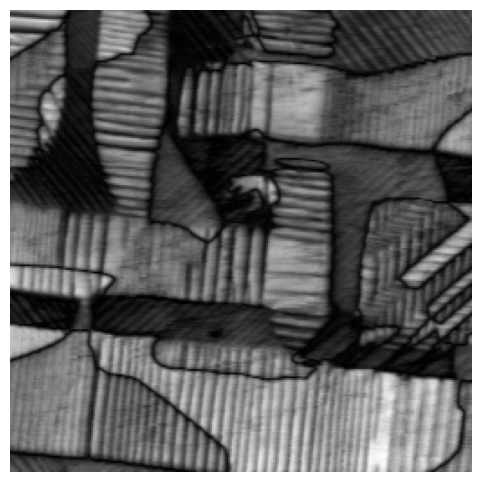

In [6]:
channel_index = 2 #--> we want amplitude

img = img_data[channel_index].T
img = (img - img.min()) / (img.max() - img.min())

plt.figure(figsize=(6, 6))

plt.imshow(
    img,
    cmap="gray"
)

plt.axis("off")
plt.show()

Each trace contains multiple decision steps.

For every step:

- `patches` contains all candidate image patches available to the agent.
- `selected_candidate` gives the candidate selected by the agent.
- `selected_patch` contains the selected image patch.
- `position` gives the selected location in the original AFM image.
- `score` may be available for some traces.

In [7]:
TRACE_ID = 0
STEP = 47

trace = traces[TRACE_ID]

step_data = trace[STEP - 1]

print("Selected candidate:",
      step_data["selected_candidate"])

print("Position:",
      step_data["position"])

print("Number of candidates:",
      len(step_data["patches"]))

if "score" in step_data:
    print("Score:",
          step_data["score"])

Selected candidate: 16
Position: (232, 152)
Number of candidates: 20


In [8]:
print("Trace length:", len(trace))  # Avoid printing all image arrays

Trace length: 100


VISUALIZE ONE DECISION STEP

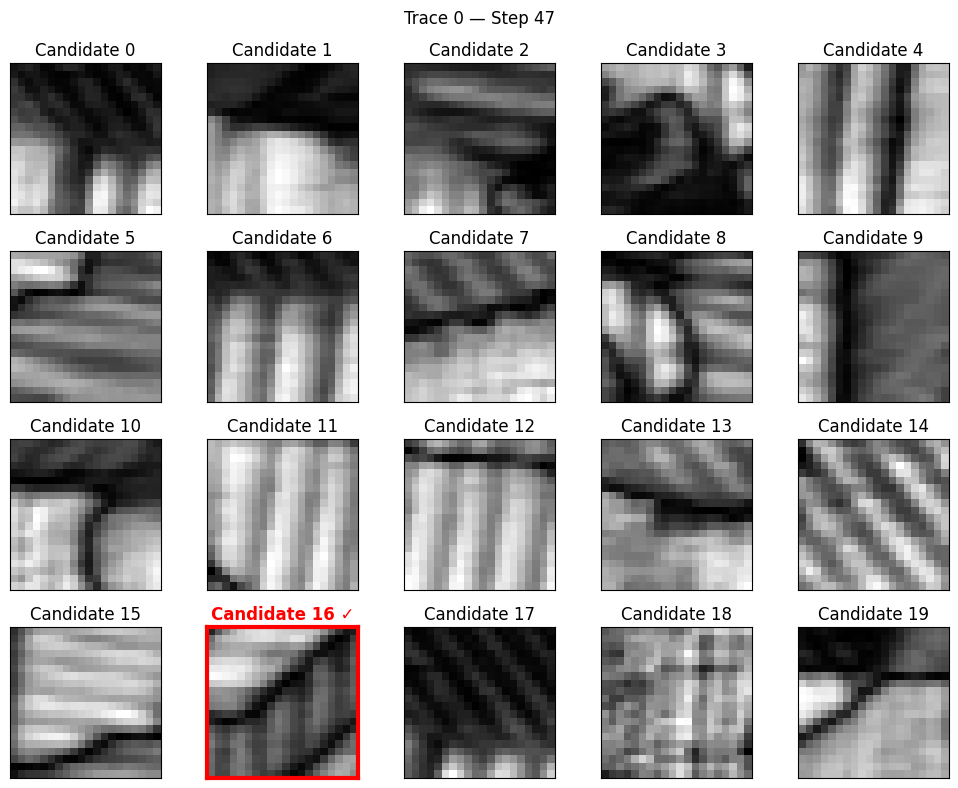

In [9]:
patches = step_data["patches"]
selected = step_data["selected_candidate"]

n = len(patches)

ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i >= n:
        ax.axis("off")
        continue

    ax.imshow(
        patches[i],
        cmap="gray"
    )

    if i == selected:

        ax.set_title(
            f"Candidate {i} ✓",
            color="red",
            weight="bold"
        )

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)

    else:

        ax.set_title(
            f"Candidate {i}"
        )

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(
    f"Trace {TRACE_ID} — Step {STEP}"
)

plt.tight_layout()
plt.show()

TRACE MAP ON ORIGINAL IMAGE

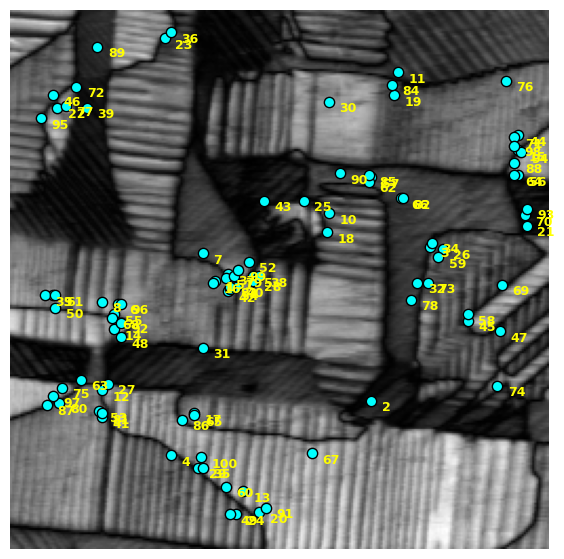

In [10]:
trace = traces[TRACE_ID]

steps = sorted(trace.keys())

xs = [
    trace[step]["position"][0]
    for step in steps
]

ys = [
    trace[step]["position"][1]
    for step in steps
]


fig, ax = plt.subplots(
    figsize=(7, 7)
)

ax.imshow(
    img,
    cmap="gray"
)


# ------------------------------------------------------------
# Plot all selected locations
# ------------------------------------------------------------

ax.scatter(
    xs,
    ys,
    s=55,
    color="cyan",
    edgecolors="black"
)


# ------------------------------------------------------------
# Label each point by decision step
# ------------------------------------------------------------

for step, x, y in zip(
    steps,
    xs,
    ys
):

    ax.text(
        x + 5,
        y + 5,
        str(step + 1),
        fontsize=9,
        color="yellow",
        weight="bold"
    )


ax.axis("off")

plt.show()

DECISION MAPS FOR 10 TRACES

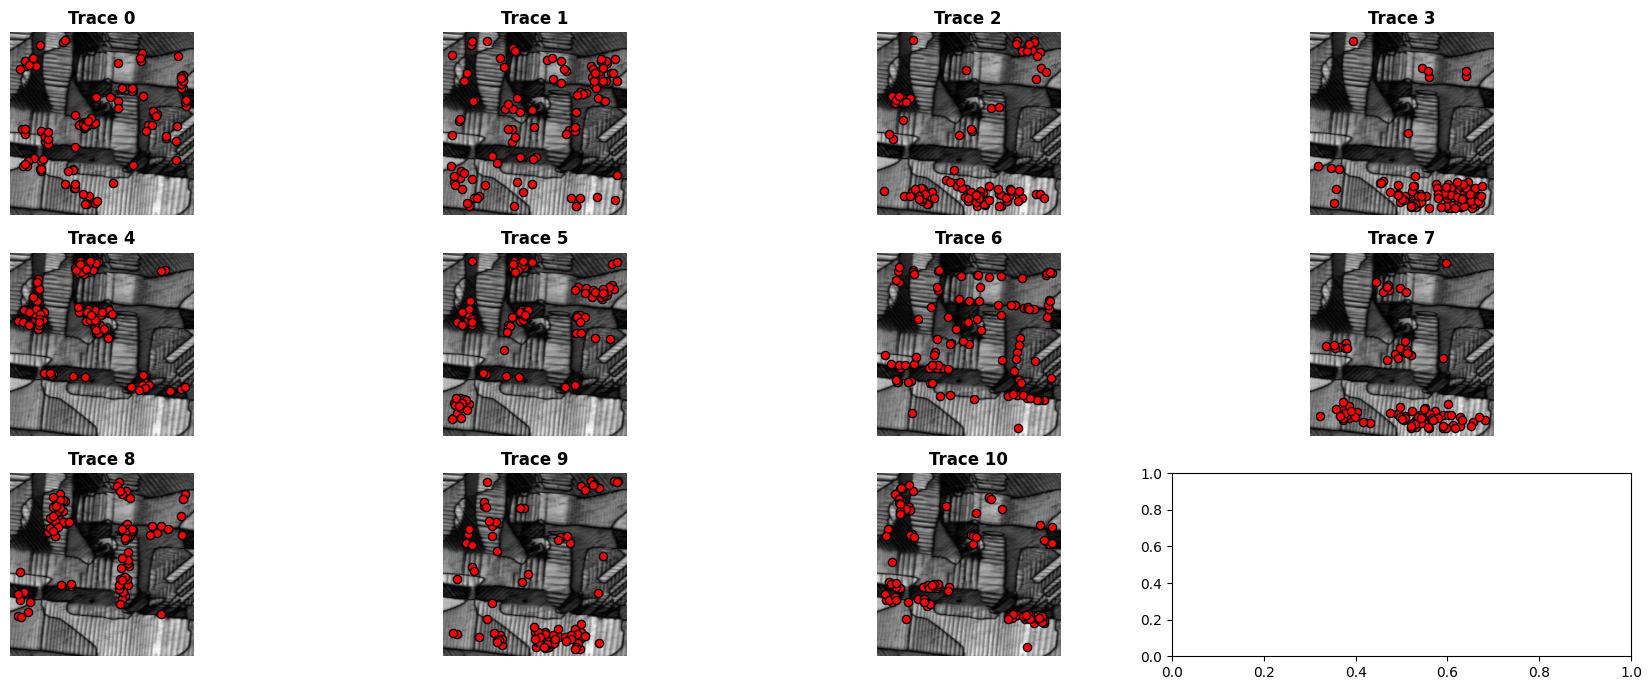

In [11]:
TRACE_IDS = list(traces.keys())

fig, axes = plt.subplots(
    3,
    4,
    figsize=(18, 7)
)

axes = axes.flatten()


for ax, trace_id in zip(axes, TRACE_IDS):

    trace = traces[trace_id]

    steps = sorted(trace.keys())

    xs = [
        trace[step]["position"][0]
        for step in steps
    ]

    ys = [
        trace[step]["position"][1]
        for step in steps
    ]


    # Original AFM image
    ax.imshow(
        img,
        cmap="gray"
    )


    # Selected locations
    ax.scatter(
        xs,
        ys,
        s=35,
        color="r",
        edgecolors="black"
    )

    ax.set_title(
        f"Trace {trace_id}",
        fontsize=12,
        weight="bold"
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

# What Makes a Patch Get Selected?

Each decision step contains 20 candidate patches, but only one was selected.
The goal is to discover visual or quantitative characteristics that may explain the hidden objective.

### DEFINE YOUR HYPOTHESIZED REWARD

In [12]:
def reward(patch):

    p = patch.astype(float)

    # --------------------------------------------------------
    # YOUR HYPOTHESIS HERE
    # --------------------------------------------------------

    score = np.mean(p)   # example only — modify this

    return score


### SCORE ALL PATCHES IN ONE STEP

In [13]:
TRACE_ID = 0
STEP = 80

trace = traces[TRACE_ID]
step_data = trace[STEP - 1]

patches = step_data["patches"]
actual_selected = step_data["selected_candidate"]


# Score all 20 candidates
scores = np.array([
    reward(patch)
    for patch in patches
])


# Select highest-scoring candidate
predicted_selected = int(
    np.argmax(scores)
)

print(
    f"Actual selection:    Candidate {actual_selected}"
)

print(
    f"Predicted selection: Candidate {predicted_selected}"
)

Actual selection:    Candidate 11
Predicted selection: Candidate 7



### VISUALIZE PREDICTED vs ACTUAL CLEARLY

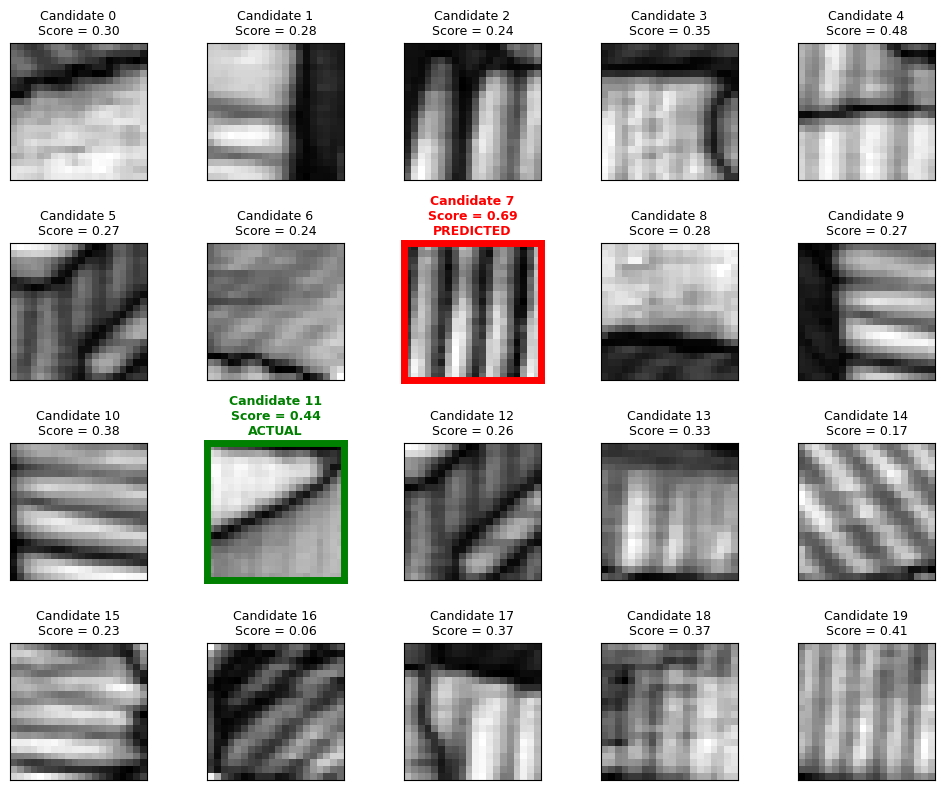

In [14]:
fig, axes = plt.subplots(
    4,
    5,
    figsize=(10, 8)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        patches[i],
        cmap="gray"
    )

    ax.set_title(
        f"Candidate {i}\nScore = {scores[i]:.2f}",
        fontsize=9
    )

    # --------------------------------------------------------
    # Highlight selections
    # --------------------------------------------------------

    if i == actual_selected and i == predicted_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("blue")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"ACTUAL + PREDICTED",
            fontsize=9,
            color="blue",
            weight="bold"
        )

    elif i == actual_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("green")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"ACTUAL",
            fontsize=9,
            color="green",
            weight="bold"
        )

    elif i == predicted_selected:

        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(5)

        ax.set_title(
            f"Candidate {i}\n"
            f"Score = {scores[i]:.2f}\n"
            f"PREDICTED",
            fontsize=9,
            color="red",
            weight="bold"
        )

    ax.set_xticks([])
    ax.set_yticks([])


plt.tight_layout()
plt.show()

### BENCHMARK HYPOTHESIZED REWARD ACROSS ALL STEPS

In [15]:
results = []

for step in sorted(trace.keys()):

    step_data = trace[step]

    patches = step_data["patches"]
    actual_selected = step_data["selected_candidate"]

    # Score all candidates in this step
    scores = np.array([
        reward(patch)
        for patch in patches
    ])

    # Predicted choice = highest score
    predicted_selected = int(
        np.argmax(scores)
    )

    results.append({
        "step": step + 1,
        "actual": actual_selected,
        "predicted": predicted_selected,
        "correct": int(
            predicted_selected == actual_selected
        )
    })


results = pd.DataFrame(results)

accuracy = results["correct"].mean()

print(f"Trace {TRACE_ID}")
print(f"Accuracy: {accuracy:.1%}")
print(f"Correct: {results['correct'].sum()} / {len(results)}")
print(f"Random baseline: {1 / len(trace[0]['patches']):.1%}")

results

Trace 0
Accuracy: 0.0%
Correct: 0 / 100
Random baseline: 5.0%


,step,actual,predicted,correct
0,1,10,18,0
1,2,9,10,0
2,3,5,6,0
3,4,15,12,0
4,5,12,0,0
...,...,...,...,...
95,96,11,19,0
96,97,5,2,0
97,98,15,12,0
98,99,1,11,0


# Day 20: interpretable decision analysis

This section runs independently of the starter cells. Place this notebook beside the 11 pickle files and the IBW image, or set `DATA_DIR` below. Install dependencies with `%pip install numpy pandas scipy matplotlib igor2` if needed. Only load pickle files supplied by a trusted source.

We model a **choice among 20 alternatives**, not independent binary labels. Decisions 1–50 train models; 51–70 choose the rule and regularization; decisions 1–70 then refit the combined model. Decisions 71–100 are held out until the final evaluation. Validation selects the entire model family before test evaluation. The test set is small (30 decisions): uncertainty is substantial. No ground truth rules are available, so recovered preferences are hypotheses, not verified mechanisms.

Image features use the supplied patch values without per-patch intensity normalization. The optional history feature uses only earlier observed selections. `score`, selected coordinates and selected-patch metadata are never predictor inputs. Candidate coordinates are not provided, so we do not infer spatial preferences from selected positions alone.


In [16]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from scipy.optimize import minimize
from scipy.special import logsumexp
from igor2 import binarywave
from IPython.display import display

DATA_DIR = Path("/Users/spuplampu/camm_hackathon/day_20/data/")
if not (DATA_DIR / 'scan_main_0000.ibw').exists():
    DATA_DIR = DATA_DIR / 'upload'
files = sorted(DATA_DIR.glob('gpt_decision_trace_*.pkl')) + sorted(DATA_DIR.glob('simulated_decision_trace_*.pkl'))
assert len(files) == 11, 'Set DATA_DIR to the folder containing all 11 traces.'
traces_named = {f.stem: pickle.load(f.open('rb')) for f in files}
wave = binarywave.load(str(DATA_DIR / 'scan_main_0000.ibw'))['wave']
channels = np.moveaxis(np.asarray(wave['wData']), -1, 0)
img = channels[2].T
img = (img-img.min())/(img.max()-img.min())
checks = []
for name, trace in traces_named.items():
    for step in sorted(trace):
        d=trace[step]; p=np.asarray(d['patches']); y=int(d['selected_candidate'])
        assert p.shape == (20,20,20) and np.isfinite(p).all()
        assert 0 <= y < 20 and np.array_equal(p[y],d['selected_patch'])
    checks.append({'trace':name,'steps':len(trace),'candidates':20,'patch_shape':'20 × 20'})
display(pd.DataFrame(checks))
print('IBW shape:', channels.shape, 'Channel labels:', wave.get('labels'))
print('Image display follows the starter notebook: transposed Amplitude2, global normalization.')


,trace,steps,candidates,patch_shape
0,gpt_decision_trace_0,100,20,20 × 20
1,gpt_decision_trace_1,100,20,20 × 20
2,gpt_decision_trace_2,100,20,20 × 20
3,simulated_decision_trace_0,100,20,20 × 20
4,simulated_decision_trace_1,100,20,20 × 20
5,simulated_decision_trace_2,100,20,20 × 20
6,simulated_decision_trace_3,100,20,20 × 20
7,simulated_decision_trace_4,100,20,20 × 20
8,simulated_decision_trace_5,100,20,20 × 20
9,simulated_decision_trace_6,100,20,20 × 20


IBW shape: (6, 256, 256) Channel labels: [[], [], [b'', b'HeightRetrace', b'Amplitude1Retrace', b'Amplitude2Retrace', b'Phase1Retracece', b'Phase2Retraceace', b'FrequencyRetrace'], []]
Image display follows the starter notebook: transposed Amplitude2, global normalization.


In [17]:
def patch_features(patch):
    p=np.asarray(patch,dtype=float)
    gy,gx=np.gradient(p); g=np.hypot(gx,gy)
    q10,q25,q50,q75,q90=np.quantile(p,[.1,.25,.5,.75,.9])
    hist=np.histogram(np.clip(p,0,1),bins=32,range=(0,1))[0]
    prob=hist[hist>0]/p.size
    center=p[5:15,5:15]; border=np.ones(p.shape,dtype=bool);border[5:15,5:15]=False
    spectrum=np.abs(np.fft.fftshift(np.fft.fft2(p-p.mean())))**2
    yy,xx=np.indices(p.shape);r=np.hypot(yy-10,xx-10)
    total=spectrum.sum()+1e-20
    return np.array([p.mean(),p.std(),q10,q50,q90,q75-q25,p.max()-p.min(),
        -np.sum(prob*np.log2(prob)),g.mean(),np.quantile(g,.9),np.mean(g*g),
        np.std(ndimage.laplace(p)),np.mean(np.abs(np.diff(p,axis=0))),
        np.mean(np.abs(np.diff(p,axis=1))),np.mean(p>.5),np.mean(p<.1),
        center.mean()-p[border].mean(),np.std(p.mean(axis=0)),np.std(p.mean(axis=1)),
        spectrum[r>5].sum()/total,spectrum[(r>0)&(r<=3)].sum()/total,
        abs(np.mean(gx*gx)-np.mean(gy*gy))/(np.mean(g*g)+1e-20)])
feature_names=['mean','std','q10','median','q90','IQR','range','entropy',
 'gradient_mean','gradient_q90','gradient_energy','laplacian_std','vertical_difference',
 'horizontal_difference','bright_fraction','dark_fraction','center_minus_border',
 'column_mean_std','row_mean_std','high_frequency_fraction','low_frequency_fraction','gradient_anisotropy']
Xbase={}; labels={}
for name,trace in traces_named.items():
    Xbase[name]=np.array([[patch_features(p) for p in trace[t]['patches']] for t in sorted(trace)])
    labels[name]=np.array([trace[t]['selected_candidate'] for t in sorted(trace)],dtype=int)
print('Feature tensors:', {k:v.shape for k,v in Xbase.items()})


Feature tensors: {'gpt_decision_trace_0': (100, 20, 22), 'gpt_decision_trace_1': (100, 20, 22), 'gpt_decision_trace_2': (100, 20, 22), 'simulated_decision_trace_0': (100, 20, 22), 'simulated_decision_trace_1': (100, 20, 22), 'simulated_decision_trace_2': (100, 20, 22), 'simulated_decision_trace_3': (100, 20, 22), 'simulated_decision_trace_4': (100, 20, 22), 'simulated_decision_trace_5': (100, 20, 22), 'simulated_decision_trace_6': (100, 20, 22), 'simulated_decision_trace_7': (100, 20, 22)}


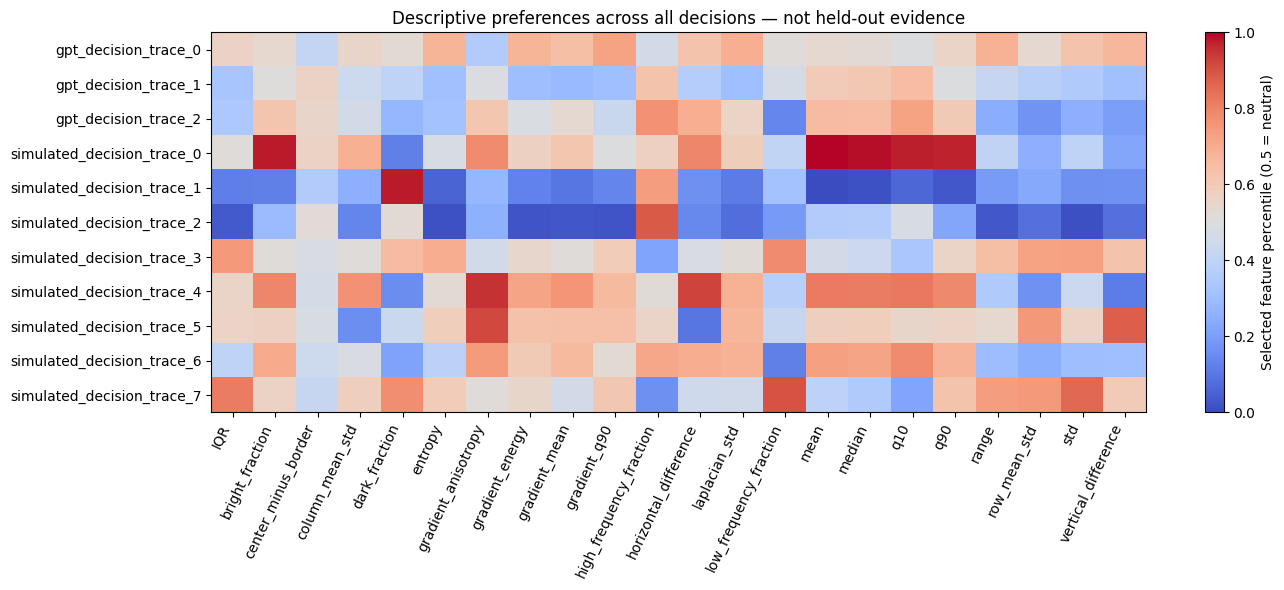

In [18]:
# Signed feature preferences: percentile of selected feature within each choice set.
# Midranks correctly handle ties. 0.5 is the random-choice expectation.
preference=[]
for name,X in Xbase.items():
    y=labels[name]
    for k,feature in enumerate(feature_names):
        ranks=stats.rankdata(X[:,:,k],axis=1,method='average')
        percent=(ranks[np.arange(len(y)),y]-1)/19
        preference.append({'trace':name,'feature':feature,'selected_percentile':percent.mean()})
pref=pd.DataFrame(preference).pivot(index='trace',columns='feature',values='selected_percentile')
fig,ax=plt.subplots(figsize=(14,6))
im=ax.imshow(pref.values,vmin=0,vmax=1,cmap='coolwarm',aspect='auto')
ax.set_xticks(range(len(pref.columns)),pref.columns,rotation=65,ha='right')
ax.set_yticks(range(len(pref)),pref.index)
fig.colorbar(im,ax=ax,label='Selected feature percentile (0.5 = neutral)')
ax.set_title('Descriptive preferences across all decisions — not held-out evidence')
plt.tight_layout();plt.show()


In [19]:
def fit_choice(X,y,penalty):
    # Training-only global scaling; choice-set centering leaves softmax unchanged.
    mean=X.mean(axis=(0,1));scale=X.std(axis=(0,1));scale=np.maximum(scale,1e-10)
    Z=(X-mean)/scale;Z=Z-Z.mean(axis=1,keepdims=True)
    def objective(b):
        u=Z@b;lp=u-logsumexp(u,axis=1,keepdims=True);prob=np.exp(lp)
        loss=-lp[np.arange(len(y)),y].mean()+penalty*np.dot(b,b)/2
        grad=np.einsum('tj,tjk->k',prob,Z)/len(y)-Z[np.arange(len(y)),y].mean(axis=0)+penalty*b
        return loss,grad
    result=minimize(objective,np.zeros(X.shape[-1]),jac=True,method='L-BFGS-B',options={'maxiter':600})
    if not result.success: raise RuntimeError(result.message)
    return mean,scale,result.x

def utility(model,X):
    mean,scale,b=model
    return ((X-mean)/scale)@b

def accuracy(u,y):return np.mean(np.argmax(u,axis=1)==y)

def wilson(k,n):
    z=1.96;p=k/n;den=1+z*z/n
    mid=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return mid-half,mid+half

summaries=[];rule_tables={};coefficients={};test_predictions={}
for name,X in Xbase.items():
    y=labels[name];assert len(y)==100
    # Squares can represent intermediate target preferences. History novelty is
    # distance in appearance-feature space to previous actual selections.
    mu=X[:50].mean(axis=(0,1));sd=np.maximum(X[:50].std(axis=(0,1)),1e-10)
    Z=(X-mu)/sd
    novelty=np.zeros((100,20))
    for t in range(1,100):
        previous=Z[np.arange(t),y[:t]]
        novelty[t]=np.sqrt(((Z[t,:,None,:]-previous[None,:,:])**2).mean(axis=-1)).min(axis=1)
    augmented=np.concatenate([Z,np.clip(Z,-8,8)**2,novelty[:,:,None]],axis=2)
    augnames=feature_names+[f'{f}²' for f in feature_names]+['history_appearance_novelty']
    options=[];simple=[]
    for k,f in enumerate(feature_names):
        for sign,label in [(1,'maximize'),(-1,'minimize')]:
            u=sign*X[:,:,k]
            val=accuracy(u[50:70],y[50:70])
            options.append((val,f'{label} {f}',u,None))
            simple.append({'rule':f'{label} {f}','train_accuracy':accuracy(u[:50],y[:50]),'validation_accuracy':val})
    for family,A,names in [('linear',X,feature_names),('quadratic_history',augmented,augnames)]:
        for penalty in [.01,.1,1.,10.]:
            model=fit_choice(A[:50],y[:50],penalty)
            val=accuracy(utility(model,A[50:70]),y[50:70])
            options.append((val,f'{family} λ={penalty}',None,(family,A,names,penalty)))
    # Ties favor simple rules because they enter options first.
    best=max(options,key=lambda v:v[0]);val,label,u,details=best
    if details:
        family,A,names,penalty=details
        model=fit_choice(A[:70],y[:70],penalty);u=utility(model,A)
        coefficients[name]=pd.Series(model[2],index=names).sort_values(key=abs,ascending=False)
    pred=np.argmax(u[70:],axis=1);correct=int(np.sum(pred==y[70:]));lo,hi=wilson(correct,30)
    # Baseline chooses most common training candidate index, never test labels.
    index_choice=np.bincount(y[:70],minlength=20).argmax()
    test_predictions[name]=pred
    summaries.append({'trace':name,'chosen_model':label,'validation_accuracy':val,'test_correct':correct,
      'test_n':30,'test_accuracy':correct/30,'95%_low':lo,'95%_high':hi,
      'index_baseline_accuracy':np.mean(y[70:]==index_choice)})
    rule_tables[name]=pd.DataFrame(simple).sort_values('validation_accuracy',ascending=False)
summary=pd.DataFrame(summaries)
display(summary.round(3))
print('Uniform random baseline: 5%. Model selection uses validation only.')
print('History evaluation conditions on previous real selections; this is not autonomous rollout.')
for name in traces_named:
    print('\n',name,'— strongest simple hypotheses on validation')
    display(rule_tables[name].head(3).round(3))
    if name in coefficients:
        print('Largest standardized utility coefficients (correlated features are not causal effects):')
        display(coefficients[name].head(8).round(3))


,trace,chosen_model,validation_accuracy,test_correct,test_n,test_accuracy,95%_low,95%_high,index_baseline_accuracy
0,gpt_decision_trace_0,linear λ=0.01,0.45,9,30,0.300,0.167,0.479,0.067
1,gpt_decision_trace_1,linear λ=0.01,0.40,9,30,0.300,0.167,0.479,0.100
2,gpt_decision_trace_2,minimize low_frequency_fraction,0.60,12,30,0.400,0.246,0.577,0.067
3,simulated_decision_trace_0,maximize mean,0.95,30,30,1.000,0.886,1.000,0.000
4,simulated_decision_trace_1,minimize mean,1.00,30,30,1.000,0.886,1.000,0.067
5,simulated_decision_trace_2,linear λ=0.1,0.90,28,30,0.933,0.787,0.982,0.067
6,simulated_decision_trace_3,minimize high_frequency_fraction,0.25,4,30,0.133,0.053,0.297,0.100
7,simulated_decision_trace_4,quadratic_history λ=0.1,0.95,23,30,0.767,0.591,0.882,0.000
8,simulated_decision_trace_5,linear λ=0.01,0.95,26,30,0.867,0.703,0.947,0.000
9,simulated_decision_trace_6,quadratic_history λ=10.0,0.60,13,30,0.433,0.274,0.608,0.067


Uniform random baseline: 5%. Model selection uses validation only.
History evaluation conditions on previous real selections; this is not autonomous rollout.

 gpt_decision_trace_0 — strongest simple hypotheses on validation


,rule,train_accuracy,validation_accuracy
22,maximize laplacian_std,0.16,0.20
39,minimize high_frequency_fraction,0.00,0.15
14,maximize entropy,0.14,0.15


Largest standardized utility coefficients (correlated features are not causal effects):


laplacian_std            1.689
gradient_mean           -1.512
vertical_difference     -1.312
gradient_q90             1.207
row_mean_std            -1.124
horizontal_difference   -1.031
gradient_energy          0.936
entropy                  0.805
dtype: float64

...

low_frequency_fraction²       0.123
low_frequency_fraction       -0.105
gradient_anisotropy²          0.068
history_appearance_novelty   -0.063
bright_fraction²              0.062
horizontal_difference²        0.061
horizontal_difference         0.054
q10²                          0.051
dtype: float64


 simulated_decision_trace_7 — strongest simple hypotheses on validation


,rule,train_accuracy,validation_accuracy
36,maximize row_mean_std,0.42,0.50
33,minimize center_minus_border,0.16,0.45
2,maximize std,0.34,0.45


Largest standardized utility coefficients (correlated features are not causal effects):


entropy                  -2.584
std                       2.538
gradient_mean            -1.805
low_frequency_fraction    1.639
q90                       1.453
laplacian_std             1.131
bright_fraction          -0.843
vertical_difference      -0.783
dtype: float64

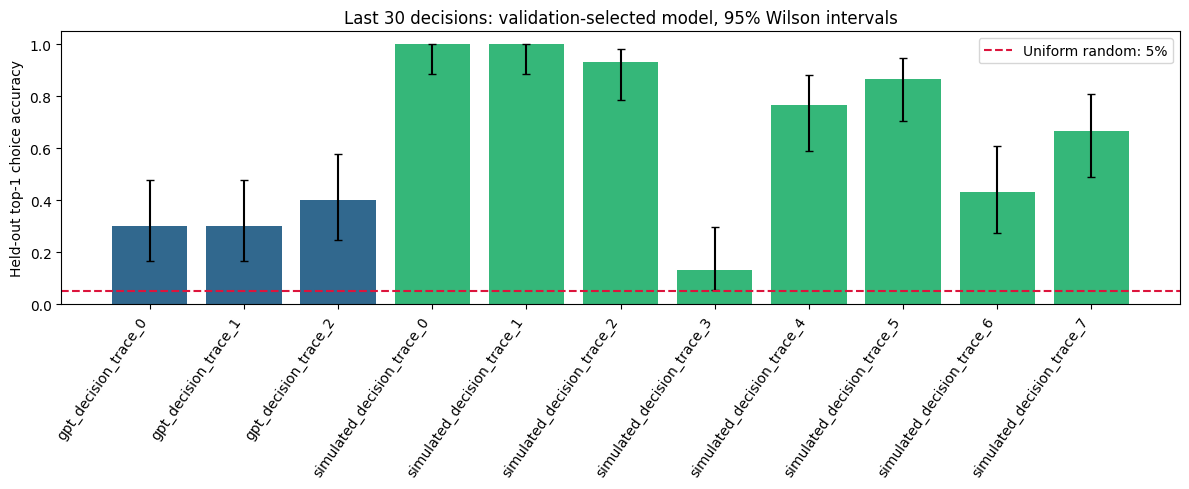

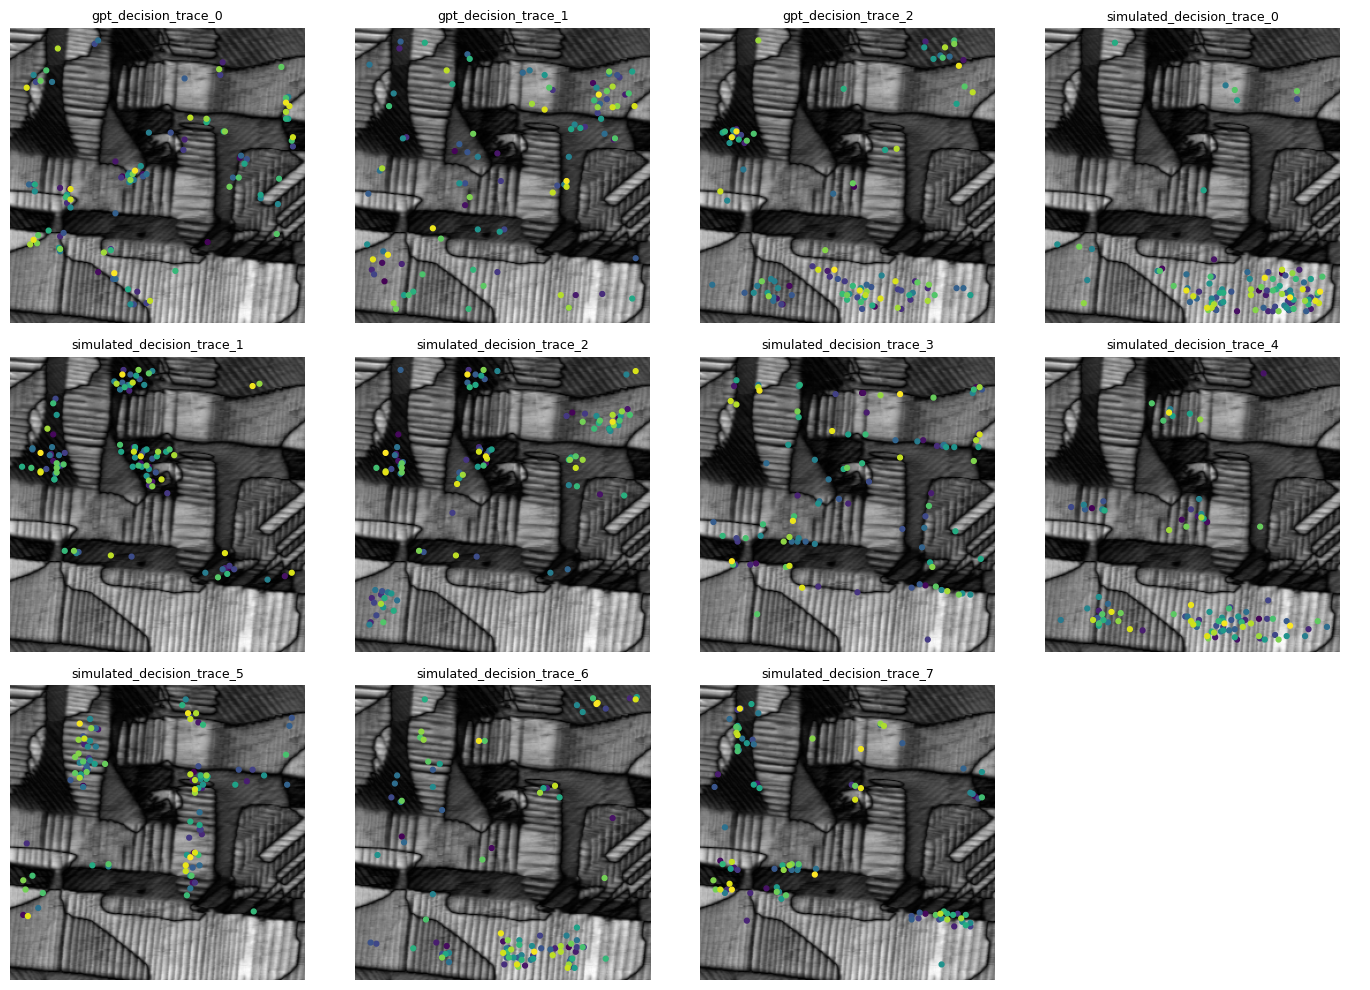

Coordinate overlay uses the starter (x,y) convention; patch-center/origin convention is not established.


In [20]:
fig,ax=plt.subplots(figsize=(12,5))
s=summary
ax.bar(np.arange(len(s)),s.test_accuracy,color=['#31688e']*3+['#35b779']*8)
ax.errorbar(np.arange(len(s)),s.test_accuracy,
 yerr=[s.test_accuracy-s['95%_low'],s['95%_high']-s.test_accuracy],fmt='none',color='black',capsize=3)
ax.axhline(.05,color='crimson',linestyle='--',label='Uniform random: 5%')
ax.set_xticks(np.arange(len(s)),s.trace,rotation=55,ha='right')
ax.set_ylabel('Held-out top-1 choice accuracy');ax.set_ylim(0,1.05)
ax.set_title('Last 30 decisions: validation-selected model, 95% Wilson intervals')
ax.legend();plt.tight_layout();plt.show()

# All 11 traces; selected coordinates are shown descriptively only.
fig,axes=plt.subplots(3,4,figsize=(14,10))
for ax,(name,t) in zip(axes.flat,traces_named.items()):
    xy=np.array([t[k]['position'] for k in sorted(t)])
    ax.imshow(img,cmap='gray');ax.scatter(xy[:,0],xy[:,1],c=np.arange(len(xy)),cmap='viridis',s=12)
    ax.set_title(name,fontsize=9);ax.axis('off')
axes.flat[-1].axis('off');plt.tight_layout();plt.show()
print('Coordinate overlay uses the starter (x,y) convention; patch-center/origin convention is not established.')


## How to interpret these results

- A high selected percentile indicates preference for larger values; a low percentile indicates preference for smaller ones. Correlated features can describe the same visual behavior.
- Held-out accuracy measures how well a rule predicts a new candidate set. It does not identify a unique generating algorithm or an agent's internal reasoning.
- The eight simulated traces remain unlabeled benchmarks. Without organizer ground truth, agreement with their choices cannot verify exact rule recovery.
- Scores in the supplied simulated data must not be used as inputs: they are recorded after selection. All pixel features and novelty scores are calculated independently.
- The rule search and combined models are exploratory. Repeated tuning after reading test results would contaminate the holdout; use new organizer data for the next confirmation.
- Location/history hypotheses require coordinates for **all** candidates or independently validated patch-to-image matching. Selected locations alone are insufficient.
- Apparent brightness is Amplitude2 signal, not surface height. Topography, physical roughness and domain interpretations require appropriate channels and calibration.

Next useful experiments: obtain candidate coordinates and display/normalization details; compare selected versus rejected patches under a common color scale; test whether position or appearance novelty improves prediction on a fresh trace; ask the organizers to reveal simulated rules after submitting predictions.


## Initial findings from the supplied data

On the 30 held-out decisions per trace:

| Trace | Accuracy | Initial interpretation |
|---|---:|---|
| GPT 0 | 30% | Combined texture/gradient preference; no single feature establishes a clear rule. |
| GPT 1 | 30% | Combined intensity/gradient preference; coefficients are not causal explanations. |
| GPT 2 | 40% | Minimizing the fraction of low-frequency spectral energy predicts some choices. |
| Simulated 0 | 100% | Maximize mean patch intensity. |
| Simulated 1 | 100% | Minimize mean patch intensity. |
| Simulated 2 | 93% | Combined model favors lower entropy/contrast and lower gradient magnitudes. |
| Simulated 3 | 13% | Poorly explained by the tested features. |
| Simulated 4 | 77% | Directional texture features dominate the fitted nonlinear model. |
| Simulated 5 | 87% | Strong directional-gradient preference. |
| Simulated 6 | 43% | Partially explained by nonlinear appearance/history model. |
| Simulated 7 | 67% | Mixed contrast, entropy and texture preferences. |

These interpretations describe fitted models, not the unavailable generating rules. Accuracy is based on only 30 tests each. The model family was selected on validation decisions; subsequent refinement requires fresh confirmation data. A history model winning does not demonstrate memory: it also includes nonlinear appearance features, so a separate ablation is needed.


In [ ]:
# Function to visulize all selected candidates for a given trace.

import numpy as np
import matplotlib.pyplot as plt


def plot_selected_candidates(traces, trace_id, ncols=10, cmap="gray"):
    trace = traces[trace_id]
    steps = sorted(trace.keys())

    selected_patches = [
        np.asarray(trace[step]["patches"][
            int(trace[step]["selected_candidate"])
        ])
        for step in steps
    ]

    # Shared color limits across all selected patches.
    vmin = min(p.min() for p in selected_patches)
    vmax = max(p.max() for p in selected_patches)

    nrows = int(np.ceil(len(steps) / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(1.8 * ncols, 2.0 * nrows),
        squeeze=False,
        constrained_layout=True,
    )

    for ax, step, patch in zip(axes.flat, steps, selected_patches):
        candidate = int(trace[step]["selected_candidate"])

        im = ax.imshow(
            patch,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            interpolation="nearest",
        )
        ax.set_title(
            f"Step {step + 1}\nCandidate {candidate}",
            fontsize=8,
        )
        ax.set_xticks([])
        ax.set_yticks([])

    for ax in axes.flat[len(steps):]:
        ax.axis("off")

    fig.colorbar(
        im,
        ax=axes.ravel().tolist(),
        shrink=0.6,
        pad=0.01,
        label="Patch intensity",
    )
    fig.suptitle(
        f"Trace {trace_id} — all selected candidates",
        fontsize=16,
    )

    plt.show()
    return fig, axes




# Choose a trace from the original notebook:
# 0–2: GPT traces; 3–10: simulated traces. Example use below:
# fig, axes = plot_selected_candidates(traces, trace_id=10)


## Trace 0

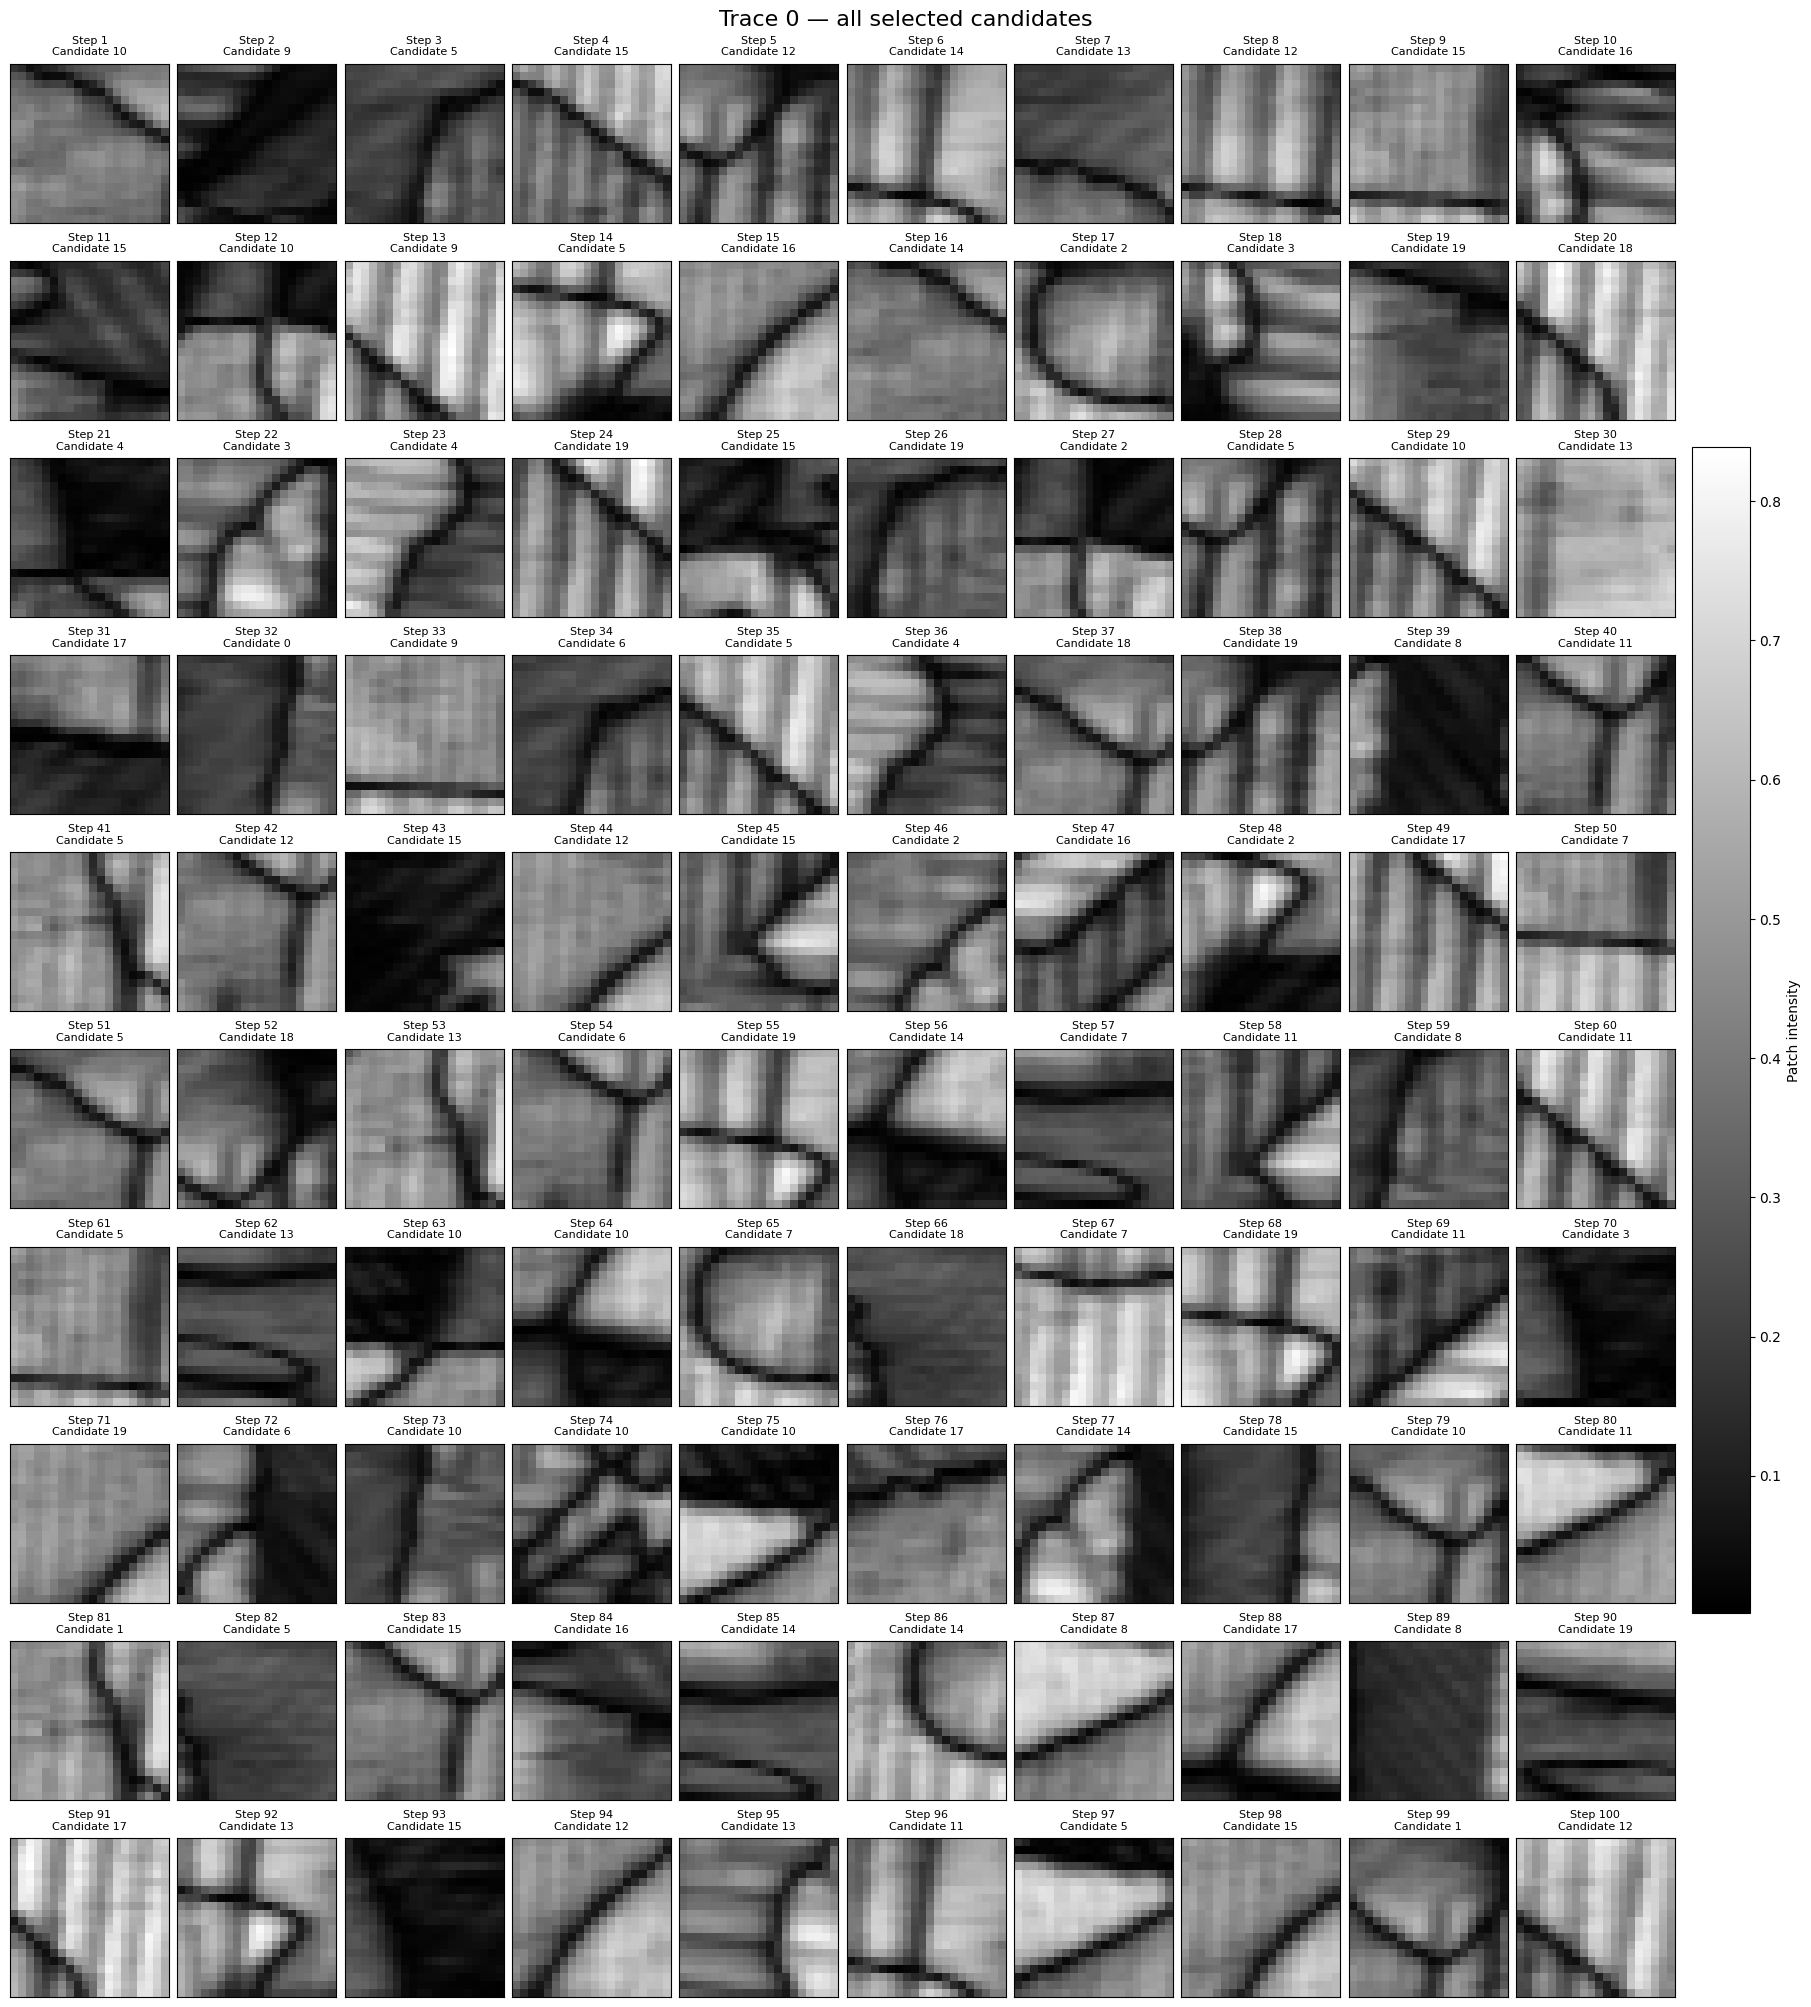

In [23]:


# Choose a trace from the original notebook:
# 0–2: GPT traces; 3–10: simulated traces.
fig, axes = plot_selected_candidates(traces, trace_id=0)

In [24]:
"""
For trace 0 try selecting patches that have one
significantly darker line that has some curvature (not straight)
"""

import numpy as np
import pandas as pd
from scipy import ndimage


def curved_dark_line_features(patch, darkness_threshold=1.0):
    """
    Detect a dominant dark component and estimate its curvature.

    darkness_threshold: minimum darkness relative to local background,
                        measured in robust residual standard deviations.
    """
    p = np.asarray(patch, dtype=float)

    empty = {
        "contrast": 0.0,
        "dominance": 0.0,
        "elongation": 0.0,
        "bend_pixels": 0.0,
        "fit_improvement": 0.0,
        "score": 0.0,
    }

    if p.ndim != 2 or not np.isfinite(p).all():
        raise ValueError("patch must be a finite 2D array.")

    if np.ptp(p) == 0:
        return empty

    # A dark line should lie below its surrounding local background.
    smooth = ndimage.gaussian_filter(p, sigma=0.7)
    background = ndimage.gaussian_filter(smooth, sigma=3.0)
    darkness = background - smooth

    median = np.median(darkness)
    scale = 1.4826 * np.median(np.abs(darkness - median))
    scale = max(scale, 0.1 * darkness.std(), 1e-12)

    mask = (
        darkness > median + darkness_threshold * scale
    ) & (darkness > 0)

    labels, count = ndimage.label(mask, structure=np.ones((3, 3)))
    components = []

    for label in range(1, count + 1):
        component = labels == label
        if component.sum() >= 8:
            components.append(component)

    if not components:
        return empty

    # Choose the component with the greatest integrated darkness.
    strengths = np.array([
        darkness[c].sum() for c in components
    ])
    component = components[int(np.argmax(strengths))]
    dominance = strengths.max() / strengths.sum()

    # Express its pixels in principal-axis coordinates.
    coordinates = np.column_stack(np.nonzero(component)).astype(float)
    centered = coordinates - coordinates.mean(axis=0)

    _, _, axes = np.linalg.svd(centered, full_matrices=False)
    u, v = (centered @ axes.T).T

    eigenvalues = np.linalg.eigvalsh(np.cov(centered.T))
    ratio = eigenvalues[-1] / max(eigenvalues[0], 1e-12)

    if np.ptp(u) < 6 or ratio < 2:
        return empty

    # Estimate the centerline using mean transverse position per axial bin.
    bins = np.floor(u - u.min()).astype(int)
    center_u, center_v = [], []

    for b in np.unique(bins):
        keep = bins == b
        center_u.append(u[keep].mean())
        center_v.append(v[keep].mean())

    center_u = np.asarray(center_u)
    center_v = np.asarray(center_v)

    if len(center_u) < 7:
        return empty

    # Scale longitudinal coordinate to approximately [-1, 1].
    x = 2 * (center_u - center_u.min()) / np.ptp(center_u) - 1

    straight = np.polyval(np.polyfit(x, center_v, 1), x)
    quadratic_coefficients = np.polyfit(x, center_v, 2)
    curved = np.polyval(quadratic_coefficients, x)

    mse_straight = np.mean((center_v - straight) ** 2)
    mse_curved = np.mean((center_v - curved) ** 2)

    # A pixel-scale floor prevents tiny deviations from appearing decisive.
    fit_improvement = np.clip(
        (mse_straight - mse_curved) / (mse_straight + 0.25),
        0, 1,
    )

    bend_pixels = abs(quadratic_coefficients[0])
    bend_weight = 1 - np.exp(-(bend_pixels / 1.5) ** 2)
    elongation = np.clip((ratio - 2) / 8, 0, 1)
    contrast = darkness[component].mean()

    score = (
        contrast
        * dominance
        * elongation
        * bend_weight
        * fit_improvement
    )

    return {
        "contrast": contrast,
        "dominance": dominance,
        "elongation": elongation,
        "bend_pixels": bend_pixels,
        "fit_improvement": fit_improvement,
        "score": score,
    }


def reward_curved_dark_line(patch):
    return curved_dark_line_features(patch)["score"]

In [25]:
trace = traces[0]
# Alternatively:
# trace = traces_named["gpt_decision_trace_0"]

rows = []

for step in sorted(trace):
    data = trace[step]

    scores = np.array([
        reward_curved_dark_line(patch)
        for patch in data["patches"]
    ])

    actual = int(data["selected_candidate"])
    winners = np.flatnonzero(scores == scores.max())

    percentile = (
        np.sum(scores < scores[actual])
        + 0.5 * (np.sum(scores == scores[actual]) - 1)
    ) / (len(scores) - 1)

    rows.append({
        "step": step + 1,
        # Fractional credit avoids arbitrary candidate-0 wins on tied scores.
        "agreement_credit": (
            1 / len(winners) if actual in winners else 0
        ),
        "selected_score_percentile": percentile,
        "all_scores_zero": np.all(scores == 0),
    })

results = pd.DataFrame(rows)

print(
    "Tie-adjusted choice agreement:",
    f"{results['agreement_credit'].mean():.1%}",
)
print(
    "Mean selected-score percentile:",
    f"{results['selected_score_percentile'].mean():.3f}",
)
print(
    "Steps with no detected curved line:",
    results["all_scores_zero"].sum(),
)
print("Random expectations: 5% agreement; 0.5 percentile.")

Tie-adjusted choice agreement: 15.0%
Mean selected-score percentile: 0.667
Steps with no detected curved line: 0
Random expectations: 5% agreement; 0.5 percentile.


In [ ]:
"""
After feeding selected patches back to ChatGPT, it produced the following summary of its own reasoning:

The strongest recurring motif is a dark boundary or trough separating brighter regions. Curvature seems optional.
Looking across the montage:
- Dark lines often span much of the patch, whether diagonal, horizontal, or vertical—for example, steps 1, 8, 15, 29, and 94.
- Bends and junctions recur, including steps 12, 37, 40, 54, and 79.
- Stripes frequently meet or terminate at the dark boundary, as in steps 4, 13, 20, and 60.
- Some selections have fairly straight boundaries, while a few lack an obvious prominent line. So “one curved dark line” appears too restrictive.
My leading hypothesis would be:
Trace 0 favors a prominent, connected dark trough that separates brighter image structures, sometimes where striped textures meet or change direction.

That suggests testing these features:
Feature	What it measures
Local trough contrast	Is the line darker than its surroundings on both sides?
Connected length	Does it extend across a substantial portion of the patch?
Separation	Does the dark structure divide brighter regions?
Junctions or bends	Does it branch or change direction?
Texture change across it	Do stripe orientation or texture differ between sides?


I would prioritize trough contrast and connected length, and treat curvature as an optional bonus. Our earlier detector explicitly penalized straight lines, which could explain some missed choices.
Selected patches alone cannot establish preference: we need to compare these properties with the 19 rejected alternatives in each step. But visually, “dark separating structure” is a stronger starting hypothesis than “curved line.”




The new criterion gives a modest improvement on all 100 decisions in trace 0:
Criterion	                    Choice agreement	Selected-score percentile
Earlier curved-line detector	15%	                            0.667
Dark separating structure	    18%	                            0.759


"""

In [29]:
from dark_structure_analysis import (
    reward_dark_structure,
    evaluate_dark_structure,
    plot_dark_structure_comparison,
)

results_dark = evaluate_dark_structure(traces[0])

print(
    "Tie-adjusted choice agreement:",
    f"{results_dark['agreement_credit'].mean():.1%}",
)
print(
    "Mean selected-score percentile:",
    f"{results_dark['selected_score_percentile'].mean():.3f}",
)
print(
    "Steps with no detected structure:",
    results_dark["all_scores_zero"].sum(),
)

Tie-adjusted choice agreement: 18.0%
Mean selected-score percentile: 0.759
Steps with no detected structure: 0


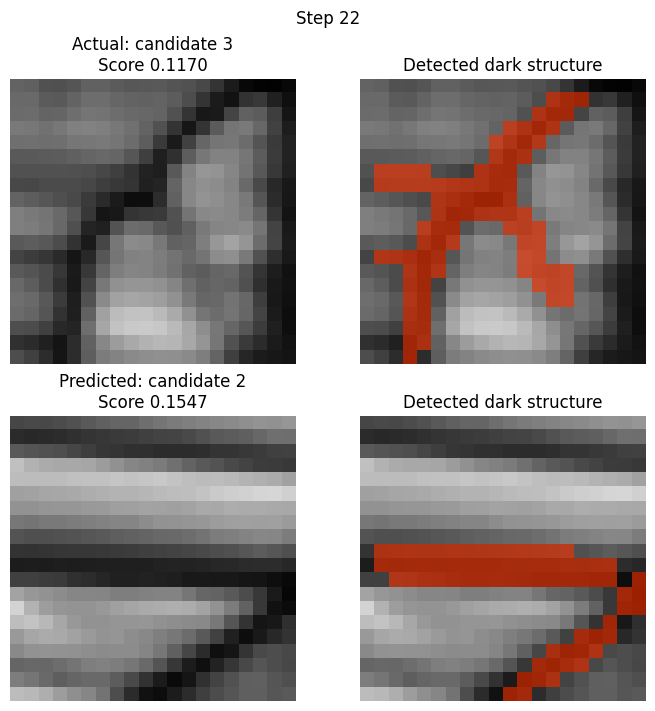

(<Figure size 700x700 with 4 Axes>,
 array([[<Axes: title={'center': 'Actual: candidate 3\nScore 0.1170'}>,
         <Axes: title={'center': 'Detected dark structure'}>],
        [<Axes: title={'center': 'Predicted: candidate 2\nScore 0.1547'}>,
         <Axes: title={'center': 'Detected dark structure'}>]],
       dtype=object))

In [34]:
# step=0 means the first decision.
plot_dark_structure_comparison(traces[0], step=21)